# 14 · Shariah-compliant companies worldwide: how many pass, and do they perform differently?
Islamic equity indices screen companies on their business and on their balance sheet. This notebook applies an **asset-based screen** in the style of the FTSE Shariah and AAOIFI standards to every non-financial company in the panel:

| Screen | Threshold |
|---|---|
| Business | Conventional finance, insurance (excluded from the panel), and tobacco are excluded |
| Interest-bearing debt / total assets | below 33.3% |
| Cash and interest-bearing deposits / total assets | below 33.3% |
| Receivables + cash / total assets | below 50% |

Limits of this version: income from impermissible activities (the 5% rule) cannot be measured from Compustat, so the business screen is coarse. Alcohol producers and casinos sit inside broader GICS industries and are not removed. Indices that use market capitalisation instead of total assets pass more firms in rising markets.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
# raw statement items, same rows and order as the panel (scripts/build_panel.py); private, never published
r = pd.read_parquet(PANEL.with_name("panel_raw.parquet"))
assert (r[["gvkey", "fyear"]].to_numpy() == p[["gvkey", "fyear"]].to_numpy()).all()
p = pd.concat([p, r.drop(columns=["gvkey", "fyear"]).add_prefix("x_")], axis=1)
def wins(s, by=None, lo=0.01, hi=0.99):
    s = s.replace([np.inf, -np.inf], np.nan); by = p.loc[s.index, "fyear"] if by is None else by
    return s.clip(s.groupby(by).transform(lambda v: v.quantile(lo)), s.groupby(by).transform(lambda v: v.quantile(hi)), axis=0)
p = p.sort_values(["gvkey", "fyear"]).reset_index(drop=True)
def lag(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(k); gap = p["fyear"] - g["fyear"].shift(k)
    return v.where(gap == k)
def lead(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(-k); gap = g["fyear"].shift(-k) - p["fyear"]
    return v.where(gap == k)
# approximate annual stock returns (Compustat North America): fiscal-year-end price plus dividends per share.
# Years in which shares outstanding changed by more than 10% are dropped, which removes stock splits that the
# unadjusted price would misread as losses. Firms that delisted have no final return, so returns are biased upward.
na = (p["source"] == "North America") & p["loc"].isin(["USA", "CAN"])
pr, sh = p.x_prcc_f.where(na & (p.x_prcc_f > 0)), p.x_csho.where(p.x_csho > 0)
p["mv"] = pr * sh
p["dps"] = (p.x_dvt.fillna(0) / sh)
p["ret_next"] = ((lead("x_prcc_f") + lead("dps")) / pr - 1).where((lead("x_csho") / sh).between(0.9, 1.1) & (pr >= 1))
p["ret_next"] = p.ret_next.clip(-1, 5)
debt = p.x_dlc.fillna(0) + p.x_dltt.fillna(0)
p["s_debt"] = debt / p.x_at; p["s_cash"] = p.x_che / p.x_at; p["s_recv"] = (p.x_rect.fillna(0) + p.x_che) / p.x_at
p["s_business"] = ~p.x_gind.astype("string").str[:6].eq("302030")
ok = p[["s_debt", "s_cash", "s_recv"]].notna().all(axis=1)
p["pass_debt"], p["pass_cash"], p["pass_recv"] = p.s_debt < 1 / 3, p.s_cash < 1 / 3, p.s_recv < 0.5
p["compliant"] = (p.s_business & p.pass_debt & p.pass_cash & p.pass_recv).astype(float).where(ok)
print(f"screen applied to {ok.mean():.0%} of firm-years; {p.compliant.mean():.1%} pass all screens")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


screen applied to 100% of firm-years; 47.3% pass all screens


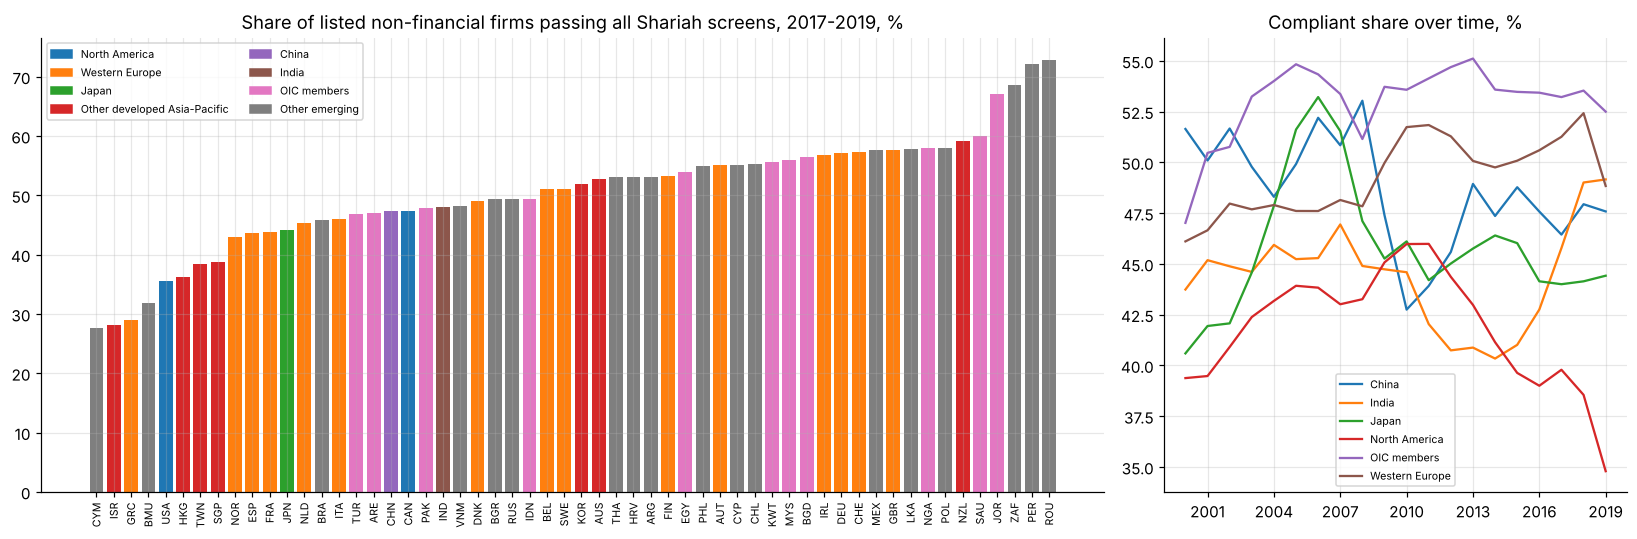

,compliant,pass_debt,pass_cash,pass_recv,firms,firm_years
region,,,,,,
North America,37.8,58.9,77.5,75.9,5004,13426
Western Europe,50.9,73.8,85.7,76.1,4524,12714
Japan,44.2,81.5,76.5,62.3,3040,8809
Other developed Asia-Pacific,43.4,76.2,75.4,67.7,7045,19931
China,47.3,83.9,76.4,65.3,4281,12600
India,47.9,65.1,94.4,79.6,3057,8681
OIC members,53.1,70.1,91.7,83.0,2943,8541
Other emerging,54.8,70.6,91.3,83.9,3708,10468


In [2]:
cs = aggregate.summary(p[p.fyear.between(2017, 2019)], "region", ["compliant", "pass_debt", "pass_cash", "pass_recv"], stat="mean").reindex(REG_ORDER)
cs[["compliant", "pass_debt", "pass_cash", "pass_recv"]] *= 100
cs.to_csv(DATA / "shariah_compliance_by_region.csv")
cty = aggregate.summary(p[p.fyear.between(2017, 2019)], "loc", ["compliant"], stat="mean", min_firms=50); cty["compliant"] *= 100
cty["region"] = cty.index.map(p.groupby("loc").region.first()); cty = cty.sort_values("compliant"); cty.to_csv(DATA / "shariah_compliance_by_country.csv")
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.3, 1]})
colors = cty.region.map(dict(zip(REG_ORDER, sns.color_palette("tab10", 8))))
ax[0].bar(cty.index, cty.compliant, color=colors); ax[0].set_title("Share of listed non-financial firms passing all Shariah screens, 2017-2019, %")
plt.setp(ax[0].get_xticklabels(), rotation=90, fontsize=7)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c, label=r_) for r_, c in zip(REG_ORDER, sns.color_palette("tab10", 8))], fontsize=7, ncol=2)
ty = p[p.fyear.le(2019) & p.region.isin(["North America", "Western Europe", "Japan", "China", "India", "OIC members"])].groupby(["fyear", "region"]).compliant.mean().unstack() * 100
ty.plot(ax=ax[1]); ax[1].set_title("Compliant share over time, %"); int_years(ax[1]); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(IMG / "shariah_compliance.png", bbox_inches="tight"); plt.show()
cs.round(1)

In [3]:
# which screen binds? share failing each screen among firms that fail
fail = p[p.compliant.eq(0) & p.fyear.between(2017, 2019)]
binds = fail.groupby("region")[["pass_debt", "pass_cash", "pass_recv", "s_business"]].apply(lambda d: 100 * (1 - d.astype(float).mean())).reindex(REG_ORDER)
binds.columns = ["fail debt %", "fail cash %", "fail receivables + cash %", "fail business %"]; binds.round(1)

,fail debt %,fail cash %,fail receivables + cash %,fail business %
region,,,,
North America,66.2,36.3,38.9,0.4
Western Europe,53.3,29.1,48.7,0.2
Japan,33.2,42.1,67.5,0.1
Other developed Asia-Pacific,42.0,43.5,57.2,0.0
China,30.6,44.9,65.8,0.1
India,67.0,10.9,39.3,0.4
OIC members,63.8,17.8,36.3,1.0
Other emerging,65.0,19.1,35.6,0.9


## Performance: compliant vs other firms of the same country, industry and year
Each outcome is compared with the average of firms in the same country, industry group and year, so differences in country and sector mix do not drive the result.

In [4]:
p["sales_growth_log"] = np.log(p.x_sale / lag("x_sale")).clip(-1.5, 1.5)
outc = {"roa": "operating ROA", "gross_margin": "gross margin", "sales_growth_log": "sales growth (log)", "z_score": "Altman Z''", "zombie": "zombie flag"}
v = p.dropna(subset=["compliant"]).copy()
cmp_ = {}
for c in outc:
    adj = v[c] - v.groupby(["loc", "industry_group", "fyear"])[c].transform("mean")
    cmp_[outc[c]] = adj.groupby([v.region, v.compliant]).mean().unstack()[1.0]
perf = pd.DataFrame(cmp_).reindex(REG_ORDER)
for c in ["operating ROA", "gross margin", "sales growth (log)", "zombie flag"]: perf[c] *= 100
perf.to_csv(DATA / "shariah_performance_gap.csv")
fe = regress.fe(v.assign(roa_pct=v.roa * 100), "roa_pct", ["compliant", "size", "sales_growth"])
print("Compliant minus peers (points). Firm and year FE: becoming compliant ->", f"{fe.loc['compliant', 'coef']:+.2f} ROA points (t = {fe.loc['compliant', 't']:.1f})")
perf.round(2)

Compliant minus peers (points). Firm and year FE: becoming compliant -> +1.85 ROA points (t = 20.9)


,operating ROA,gross margin,sales growth (log),Altman Z'',zombie flag
region,,,,,
North America,7.45,13.93,0.67,4.30,-4.13
Western Europe,2.45,3.14,0.23,0.86,-2.09
Japan,0.32,1.62,-0.13,0.41,-0.54
Other developed Asia-Pacific,3.04,7.08,0.10,1.55,-1.12
China,0.25,-0.09,0.44,-0.16,-0.3
India,0.85,2.64,-0.37,2.23,-3.42
OIC members,0.83,1.61,0.43,1.10,-2.29
Other emerging,0.56,0.75,-0.07,0.89,-1.44


In [5]:
# crisis behaviour: firms classified on their 2007 (or 2019) balance sheet
def crisis(y0, y1, label):
    a = p[p.fyear.eq(y0)].set_index("gvkey"); b = p[p.fyear.eq(y1)].set_index("gvkey"); i = a.index.intersection(b.index)
    d = a.loc[i, ["compliant", "loc", "industry_group", "region", "roa"]].copy()
    d["g"] = np.log(b.loc[i, "x_sale"] / a.loc[i, "x_sale"]).clip(-1.5, 1.5); d["droa"] = (b.loc[i, "roa"] - d.roa) * 100
    d = d.dropna(subset=["compliant", "g"])
    for c in ["g", "droa"]: d[c + "_adj"] = d[c] - d.groupby(["loc", "industry_group"])[c].transform("mean")
    t = d.groupby("compliant")[["g_adj", "droa_adj"]].mean().rename(index={0.0: "other", 1.0: "compliant"})
    t["g_adj"] *= 100; t.columns = [f"{label}: sales growth vs peers, pts", f"{label}: ROA change vs peers, pts"]; return t
cr = pd.concat([crisis(2007, 2009, "2007-09"), crisis(2019, 2020, "2019-20")], axis=1); cr.to_csv(DATA / "shariah_crisis.csv"); cr.round(2)

,"2007-09: sales growth vs peers, pts","2007-09: ROA change vs peers, pts","2019-20: sales growth vs peers, pts","2019-20: ROA change vs peers, pts"
compliant,,,,
other,0.29,0.11,0.03,0.60
compliant,-0.29,-0.11,-0.04,-0.72


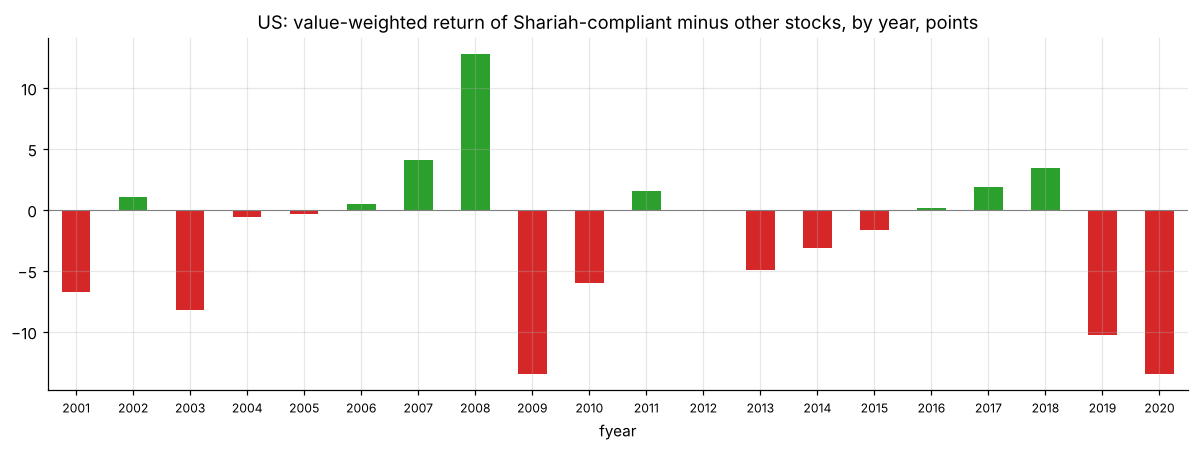

,equal-weighted,value-weighted
"compliant, mean annual return %",10.51,7.08
"other, mean annual return %",10.45,9.26
"difference, pts",0.06,-2.18
"difference in 2008, pts",3.72,12.78


In [6]:
# US stocks: next-year return of compliant and other portfolios (approximate returns, see notebook 13)
us = p[p["loc"].eq("USA") & p.ret_next.notna() & p.mv.notna() & p.compliant.notna()]
ew = us.groupby(["fyear", "compliant"]).ret_next.mean().unstack()
vw = us.groupby(["fyear", "compliant"]).apply(lambda x: np.average(x.ret_next, weights=x.mv)).unstack()
ew.index, vw.index = ew.index + 1, vw.index + 1
summ = pd.DataFrame({"equal-weighted": [100 * ew[1].mean(), 100 * ew[0].mean(), 100 * (ew[1] - ew[0]).mean(), 100 * (ew[1] - ew[0]).loc[2008]],
                     "value-weighted": [100 * vw[1].mean(), 100 * vw[0].mean(), 100 * (vw[1] - vw[0]).mean(), 100 * (vw[1] - vw[0]).loc[2008]]},
                    index=["compliant, mean annual return %", "other, mean annual return %", "difference, pts", "difference in 2008, pts"])
fig, ax = plt.subplots(figsize=(11, 4.2))
(100 * (vw[1] - vw[0])).plot.bar(ax=ax, color=np.where(vw[1] > vw[0], "C2", "C3"), rot=0)
ax.set_title("US: value-weighted return of Shariah-compliant minus other stocks, by year, points"); ax.axhline(0, color="grey", lw=0.7)
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "shariah_us_returns.png", bbox_inches="tight"); plt.show()
summ.to_csv(DATA / "shariah_us_returns.csv"); summ.round(2)

## Findings
* **About half of listed non-financial companies pass an asset-based Shariah screen (47% overall).** The share runs from 38% in North America to 51% in Western Europe and 53-55% in OIC member and other emerging markets (2017-2019). By country it ranges from under 30% in the Cayman Islands, Israel and Greece to over 65% in Saudi Arabia, Jordan, South Africa, Peru and Romania.
* **Debt is the binding screen in debt-financed markets, and cash in cash-rich Asia.** Two-thirds of failing firms in North America, India and OIC markets fail the 33% debt limit. In Japan and China, most failures come from the cash and receivables screens: Japanese firms fail on the receivables-plus-cash limit (68% of failures).
* **The North American compliant share fell from about 46% (2010) to 35% (2019)** as US leverage rose. The 2019 drop also reflects lease liabilities moving onto balance sheets (ASC 842), so the screen may need a lease adjustment.
* **Compliant firms are more profitable and safer.** Against firms of the same country, industry and year, compliant firms earn higher operating ROA (+7.5 points in North America, +2.5 in Western Europe), have higher Altman Z'' scores and are much less likely to be zombies (-4.1 points in North America, -3.4 in India). When the same firm becomes compliant, its ROA is 1.9 points higher (firm and year fixed effects, t = 21). Low debt is partly a result of profitability, so this is association, not cause.
* **The crisis protection is in the stock market, not in sales.** Classified on their 2007 balance sheets, compliant firms' sales fared no better than peers' in 2008-09 or 2020. But US Shariah-compliant stocks beat other stocks by 12.8 points (value-weighted) in 2008. Over 2001-2020 they lagged by 2.2 points a year value-weighted, giving up the 2008 gain in the 2009 and 2019-2020 rallies. Equal-weighted, returns were the same.
* **For Islamic funds and advisers:** a balance-sheet screen alone already removes half the market, and the remaining firms are a quality tilt (profitable, low-debt), with the defensive behaviour that implies.